# INF 610 - selecao Top-k

**Min-Heap, Quickselect aleatorizado e BFPRT**

Aqui comparo o custo de selecionar os `k` maiores scores. Usei o AmazoniaExpert.IA como exemplo, mas medi so a selecao (sem medir a busca no ChromaDB ou a geracao da resposta).

## 1. Configuracao

A parte sintetica roda sem outros dados. Pra testar as 130 perguntas reais, uso o ZIP `dados/reais/dados_colab_publicacao.zip`. No Google Colab, se ele nao estiver presente, a celula seguinte tenta baixar o JSON e o ZIP diretamente deste repositorio publico e confere o SHA-256. Nao precisa baixar o ChromaDB original nem montar o Google Drive.


In [1]:
from pathlib import Path
from collections import defaultdict
from statistics import median
from time import perf_counter
import csv, gc, hashlib, json, math, platform, random, sys, tracemalloc
import numpy as np
import matplotlib.pyplot as plt

SEMENTE = 6102026
NS = [300, 1500, 6000, 12000]
REPETICOES = 5
DISTRIBUICOES = ['uniforme', 'crescente', 'decrescente', 'empates']
K_REAIS = [1, 3, 5, 8, 10, 20]

BASE = Path.cwd()
PASTA_DADOS = BASE / 'dados' / 'reais'
PASTA_RESULTADOS = BASE / 'resultados'
PASTA_GRAFICOS = PASTA_RESULTADOS / 'graficos'
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)
print('Pasta de trabalho:', BASE)
# Abrir o notebook pelo GitHub no Colab nao baixa os arquivos extras.
# Por isso, no Colab busco os dois arquivos no proprio repositorio publico.
# No Jupyter local uso os arquivos da pasta e nao acesso a internet.
REPO_DADOS = 'https://raw.githubusercontent.com/AnaClaraGuerra22/INF610-TopK/main/'
SHA256_ZIP_REAL = 'cc852d73ff862e50d69a9f7920b3059122e593478ac45d78d19a10cc1f02e570'

def preparar_arquivos_colab():
    try:
        import google.colab  # presente somente no Colab
    except ImportError:
        return
    from urllib.request import urlopen
    from urllib.error import URLError, HTTPError
    for relativo, hash_esperado in [
        ('SPAmazon-QA.json', None),
        ('dados/reais/dados_colab_publicacao.zip', SHA256_ZIP_REAL),
    ]:
        destino = BASE / relativo
        if destino.is_file():
            if hash_esperado:
                h = hashlib.sha256(destino.read_bytes()).hexdigest()
                if h.lower() != hash_esperado:
                    raise ValueError(f'Arquivo local com SHA-256 diferente: {relativo}')
            print('Arquivo pronto:', relativo)
            continue
        destino.parent.mkdir(parents=True, exist_ok=True)
        temporario = destino.with_name(destino.name + '.part')
        url = REPO_DADOS + relativo
        print('Baixando do GitHub:', relativo)
        try:
            with urlopen(url, timeout=120) as resposta, temporario.open('wb') as saida:
                while True:
                    bloco = resposta.read(1024 * 1024)
                    if not bloco: break
                    saida.write(bloco)
            if hash_esperado:
                hash_obtido = hashlib.sha256(temporario.read_bytes()).hexdigest()
                if hash_obtido.lower() != hash_esperado:
                    raise ValueError(f'SHA-256 incorreto em {relativo}: {hash_obtido}')
            temporario.replace(destino)
        except Exception as erro:
            temporario.unlink(missing_ok=True)
            raise RuntimeError(f'Nao consegui obter {relativo} do repositorio publico. Confira se o arquivo foi publicado. {erro}') from erro

preparar_arquivos_colab()


Pasta de trabalho: /mnt/data/INF610_topk


## 2. Algoritmos

- Min-Heap: guardo `k` itens no heap minimo.
- Quickselect: particiono com pivo sorteado.
- BFPRT: escolho o pivo com medianas de grupos de 5.

Nos tres, a saida vai em ordem decrescente. Se dois scores empatarem, ganha o indice menor. **Uma comparacao** e uma chamada pra comparar duas chaves `(score, -indice)`; **uma movimentacao** e uma escrita em uma lista de trabalho. A copia inicial do vetor de selecao tambem conta. Nao conto a geracao dos dados nem a comparacao de referencia.

In [2]:
class Contador:
    def __init__(self, ativo=True):
        self.ativo = ativo
        self.comparacoes = 0
        self.movimentacoes = 0

    def comparar(self, x, y):
        if self.ativo:
            self.comparacoes += 1
        return (x > y) - (x < y)

    def mover(self, vezes=1):
        if self.ativo:
            self.movimentacoes += vezes


def trocar(a, i, j, cont):
    if i != j:
        a[i], a[j] = a[j], a[i]
        cont.mover(2)


def ordenar_topk(v, cont):
    # Mesmo MergeSort nos tres metodos, contando escritas no vetor auxiliar.
    a = list(v)
    cont.mover(len(a))
    aux = [None] * len(a)

    def dividir(ini, fim):
        if fim - ini <= 1:
            return
        meio = (ini + fim) // 2
        dividir(ini, meio)
        dividir(meio, fim)
        i, j, t = ini, meio, ini
        while i < meio and j < fim:
            if cont.comparar(a[i], a[j]) >= 0:
                aux[t] = a[i]; i += 1
            else:
                aux[t] = a[j]; j += 1
            cont.mover()
            t += 1
        while i < meio:
            aux[t] = a[i]; cont.mover(); i += 1; t += 1
        while j < fim:
            aux[t] = a[j]; cont.mover(); j += 1; t += 1
        for t in range(ini, fim):
            a[t] = aux[t]
            cont.mover()

    dividir(0, len(a))
    return a

def subir_heap(h, i, cont):
    while i > 0:
        pai = (i - 1) // 2
        if cont.comparar(h[i], h[pai]) >= 0:
            break
        trocar(h, i, pai, cont)
        i = pai


def descer_heap(h, i, cont):
    n = len(h)
    while True:
        menor = i
        e, d = 2 * i + 1, 2 * i + 2
        if e < n and cont.comparar(h[e], h[menor]) < 0:
            menor = e
        if d < n and cont.comparar(h[d], h[menor]) < 0:
            menor = d
        if menor == i:
            break
        trocar(h, i, menor, cont)
        i = menor


def validar_k(itens, k):
    if not isinstance(k, int) or not (0 <= k <= len(itens)):
        raise ValueError('k deve estar entre 0 e n')


def min_heap(itens, k, cont, rng=None):
    validar_k(itens, k)
    if k == 0:
        return []
    h = []
    for item in itens:
        if len(h) < k:
            h.append(item)
            cont.mover()
            subir_heap(h, len(h) - 1, cont)
        elif k and cont.comparar(item, h[0]) > 0:
            h[0] = item
            cont.mover()
            descer_heap(h, 0, cont)
    return ordenar_topk(h, cont)


def particionar(a, ini, fim, pivo, cont):
    # Maiores que o pivo ficam a esquerda, iguais no meio.
    esquerda, i, direita = ini, ini, fim
    while i <= direita:
        cmp = cont.comparar(a[i], pivo)
        if cmp > 0:
            trocar(a, esquerda, i, cont)
            esquerda += 1; i += 1
        elif cmp < 0:
            trocar(a, i, direita, cont)
            direita -= 1
        else:
            i += 1
    return esquerda, direita


def quickselect(itens, k, cont, rng=None):
    validar_k(itens, k)
    if k == 0:
        return []
    a = list(itens)
    cont.mover(len(a))
    rng = rng if rng is not None else random.Random(SEMENTE)
    ini, fim, alvo = 0, len(a) - 1, k - 1
    while ini < fim:
        pivo = a[rng.randrange(ini, fim + 1)]
        esq, dir_ = particionar(a, ini, fim, pivo, cont)
        if alvo < esq:
            fim = esq - 1
        elif alvo > dir_:
            ini = dir_ + 1
        else:
            break
    return ordenar_topk(a[:k], cont)


def insertion_sort(a, ini, fim, cont):
    for i in range(ini + 1, fim + 1):
        atual = a[i]
        j = i - 1
        while j >= ini and cont.comparar(a[j], atual) < 0:
            a[j + 1] = a[j]
            cont.mover()
            j -= 1
        if j + 1 != i:
            a[j + 1] = atual
            cont.mover()


def pivo_bfprt(a, ini, fim, cont):
    if fim - ini + 1 <= 5:
        insertion_sort(a, ini, fim, cont)
        return a[(ini + fim) // 2]
    q = ini
    for comeco in range(ini, fim + 1, 5):
        final = min(comeco + 4, fim)
        insertion_sort(a, comeco, final, cont)
        med = (comeco + final) // 2
        trocar(a, q, med, cont)
        q += 1
    meio = ini + (q - ini - 1) // 2
    selecionar_bfprt(a, ini, q - 1, meio, cont)
    return a[meio]


def selecionar_bfprt(a, ini, fim, alvo, cont):
    while ini < fim:
        pivo = pivo_bfprt(a, ini, fim, cont)
        esq, dir_ = particionar(a, ini, fim, pivo, cont)
        if alvo < esq:
            fim = esq - 1
        elif alvo > dir_:
            ini = dir_ + 1
        else:
            return


def bfprt(itens, k, cont, rng=None):
    validar_k(itens, k)
    if k == 0:
        return []
    a = list(itens)
    cont.mover(len(a))
    if k < len(a):
        selecionar_bfprt(a, 0, len(a) - 1, k - 1, cont)
    return ordenar_topk(a[:k], cont)


ALGORITMOS = {'Min-Heap': min_heap,
              'Quickselect': quickselect,
              'BFPRT': bfprt}


def como_itens(scores):
    # Indice com sinal negativo resolve empate sem depender da ordem de leitura.
    return [(float(v), -i) for i, v in enumerate(scores)]


def indices_da_saida(saida):
    return [-indice_negativo for _, indice_negativo in saida]

## 3. Testes rapidos

Antes dos benchmarks, vejo se os tres retornam exatamente os mesmos indices do `sorted` do Python. Testei `k=0`, `k=n`, repeticoes, negativos e listas pequenas.

In [3]:
def testar_algoritmos():
    exemplos = [[], [4], [1, 2, 3, 4, 5], [5, 4, 3, 2, 1],
                [3, 3, 3, 3, 3], [5, -1, 5, 10, 5, -1],
                [0.2, 0.9, 0.9, 0.3], list(range(37))]
    rng = np.random.default_rng(SEMENTE)
    for n in [2, 5, 17, 100, 301]:
        exemplos.append(rng.integers(-4, 5, size=n).tolist())
        exemplos.append(rng.normal(size=n).tolist())
    testes = 0
    for entrada in exemplos:
        itens = como_itens(entrada)
        for k in sorted(set([0, 1, 2, 5, len(itens) // 2, len(itens)])):
            if k > len(itens):
                continue
            esperado = sorted(range(len(entrada)), key=lambda i: (-entrada[i], i))[:k]
            for nome, funcao in ALGORITMOS.items():
                obtido = indices_da_saida(funcao(itens, k, Contador(), random.Random(19)))
                assert obtido == esperado, (nome, len(entrada), k, obtido, esperado)
                testes += 1
    for nome, funcao in ALGORITMOS.items():
        for k_ruim in [-1, 4]:
            try:
                funcao(como_itens([1, 2, 3]), k_ruim, Contador())
                raise AssertionError((nome, k_ruim, 'nao rejeitou k invalido'))
            except ValueError:
                testes += 1
    print('Testes de corretude:', testes, 'OK')

testar_algoritmos()

Testes de corretude: 249 OK


## 4. Medidas

A lista e o resultado esperado sao preparados fora do tempo. Guardo comparacoes e movimentacoes numa execucao. Pra tempo, rodo o mesmo codigo com a contagem desligada. `tracemalloc` mede so a memoria adicional durante a selecao (nao o vetor de scores que ja veio pronto).

In [4]:
def salvar_csv(caminho, linhas, campos):
    with Path(caminho).open('w', encoding='utf-8', newline='') as arquivo:
        writer = csv.DictWriter(arquivo, fieldnames=campos)
        writer.writeheader()
        writer.writerows(linhas)


def medir(itens, k, esperado, rep, familia, n, nome, funcao):
    semente_pivo = SEMENTE + 1009 * rep + 17 * k + 3 * n
    cont = Contador(ativo=True)
    resposta = funcao(itens, k, cont, random.Random(semente_pivo))
    assert indices_da_saida(resposta) == esperado, (familia, n, k, nome)
    sem_contagem = Contador(ativo=False)
    inicio = perf_counter()
    resposta2 = funcao(itens, k, sem_contagem, random.Random(semente_pivo))
    tempo_ms = (perf_counter() - inicio) * 1000
    assert indices_da_saida(resposta2) == esperado
    return {'grupo': familia, 'n': n, 'k': k, 'repeticao': rep,
            'algoritmo': nome, 'comparacoes': cont.comparacoes,
            'movimentacoes': cont.movimentacoes, 'tempo_ms': round(tempo_ms, 5)}


def fazer_resumo(linhas):
    grupos = defaultdict(list)
    for linha in linhas:
        grupos[(linha['grupo'], linha['n'], linha['k'], linha['algoritmo'])].append(linha)
    saida = []
    for (grupo, n, k, algoritmo), valores in sorted(grupos.items()):
        saida.append({'grupo': grupo, 'n': n, 'k': k, 'algoritmo': algoritmo,
                      'repeticoes': len(valores),
                      'comparacoes_mediana': median(x['comparacoes'] for x in valores),
                      'movimentacoes_mediana': median(x['movimentacoes'] for x in valores),
                      'tempo_ms_mediana': round(median(x['tempo_ms'] for x in valores), 5)})
    return saida

CAMPOS_BRUTOS = ['grupo', 'n', 'k', 'repeticao', 'algoritmo',
                  'comparacoes', 'movimentacoes', 'tempo_ms']
CAMPOS_RESUMO = ['grupo', 'n', 'k', 'algoritmo', 'repeticoes',
                 'comparacoes_mediana', 'movimentacoes_mediana', 'tempo_ms_mediana']


def pico_memoria_kib(itens, k, nome, rep=0):
    tracemalloc.start()
    try:
        ALGORITMOS[nome](itens, k, Contador(ativo=False), random.Random(SEMENTE + rep))
        return round(tracemalloc.get_traced_memory()[1] / 1024, 3)
    finally:
        tracemalloc.stop()

## 5. Entradas sinteticas

Quatro casos: scores uniformes, ordenados crescente/decrescente e muitos empates. O objetivo e ver a variacao de `n` e `k`, nao representar os dados reais do RAG.

In [5]:
def gerar_sintetico(n, tipo, semente):
    rng = np.random.default_rng(semente)
    if tipo == 'uniforme':
        return rng.random(n).tolist()
    if tipo == 'crescente':
        return np.linspace(0, 1, n).tolist()
    if tipo == 'decrescente':
        return np.linspace(1, 0, n).tolist()
    if tipo == 'empates':
        return rng.integers(0, 12, size=n).tolist()
    raise ValueError(tipo)


sinteticos = []
for n in NS:
    valores_k = sorted(set([1, 5, 20, max(1, n // 10)]))
    for j, tipo in enumerate(DISTRIBUICOES):
        entrada = gerar_sintetico(n, tipo, SEMENTE + n + 41 * j)
        itens = como_itens(entrada)
        for k in valores_k:
            esperado = sorted(range(n), key=lambda i: (-entrada[i], i))[:k]
            for rep in range(REPETICOES):
                for nome, funcao in ALGORITMOS.items():
                    sinteticos.append(medir(itens, k, esperado, rep, tipo, n, nome, funcao))

resumo_sintetico = fazer_resumo(sinteticos)
salvar_csv(PASTA_RESULTADOS / 'sintetico.csv', sinteticos, CAMPOS_BRUTOS)
salvar_csv(PASTA_RESULTADOS / 'resumo_sintetico.csv', resumo_sintetico, CAMPOS_RESUMO)
print('Execucoes sinteticas:', len(sinteticos))

Execucoes sinteticas: 960


## 6. Memoria

Pra nao deixar o notebook demorado, medi o pico so com o maior `n`, scores uniformes e alguns valores de `k`.

In [6]:
n_mem = NS[-1]
base_mem = como_itens(gerar_sintetico(n_mem, 'uniforme', SEMENTE + n_mem))
memoria = []
for k in sorted(set([1, 5, 20, n_mem // 10])):
    for nome in ALGORITMOS:
        for rep in range(REPETICOES):
            memoria.append({'n': n_mem, 'k': k, 'algoritmo': nome,
                            'repeticao': rep, 'pico_kib': pico_memoria_kib(base_mem, k, nome, rep)})
salvar_csv(PASTA_RESULTADOS / 'memoria_sintetico.csv', memoria,
           ['n', 'k', 'algoritmo', 'repeticao', 'pico_kib'])
print('Medidas de memoria:', len(memoria))

Medidas de memoria: 60


## 7. Graficos

Uso as medianas das repeticoes. As medidas de tempo dependem da maquina; a contagem de operacoes e mais facil de comparar entre execucoes.

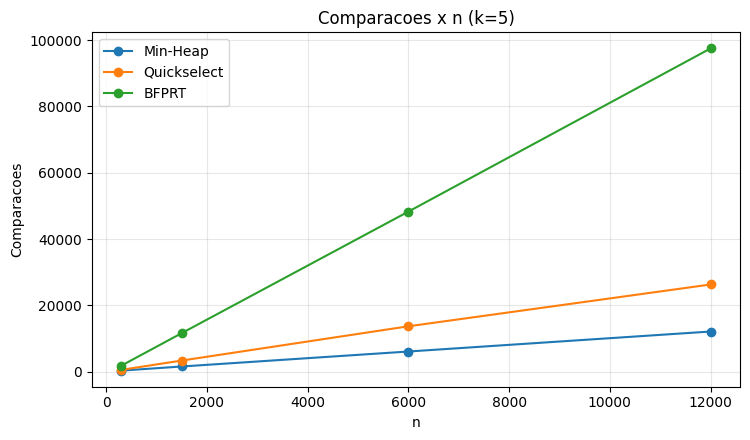

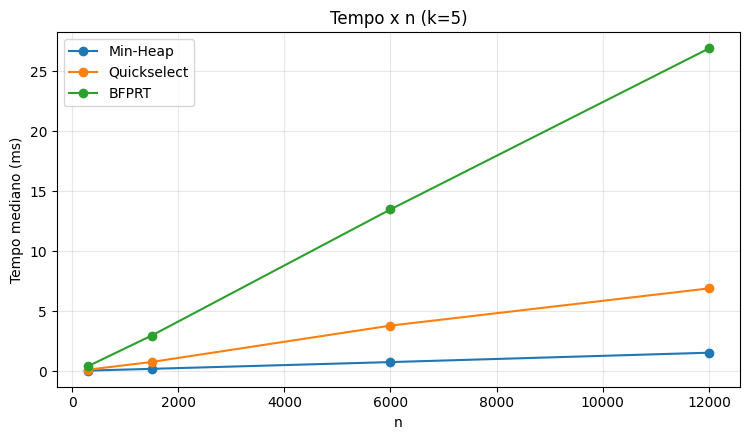

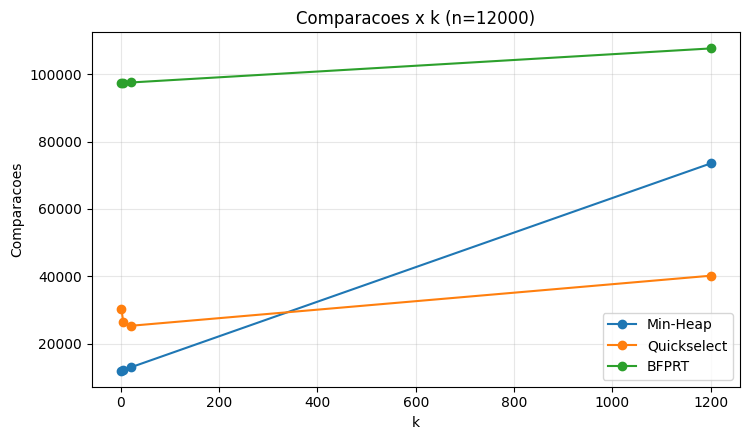

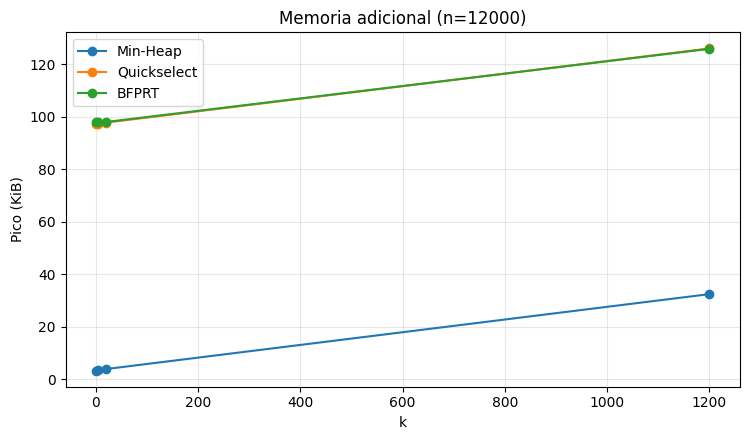

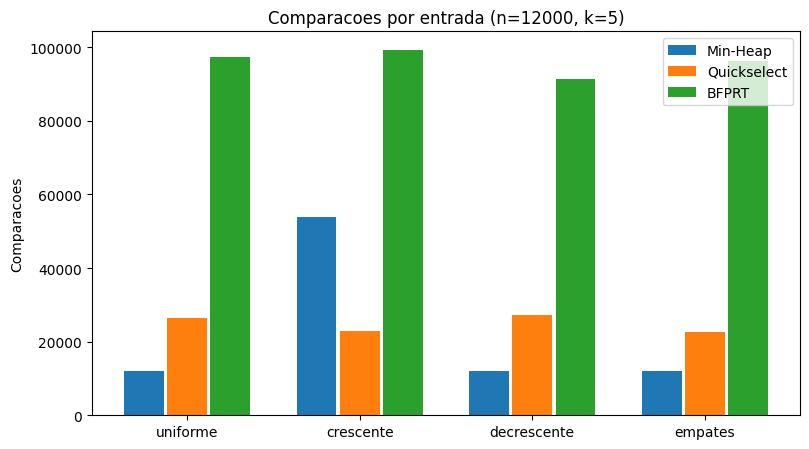

In [7]:
NOMES = list(ALGORITMOS)

def grafico_por_x(linhas, grupo, fixo, x, y, titulo, nome_arquivo, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    for algoritmo in NOMES:
        serie = [r for r in linhas if r['grupo'] == grupo and r['algoritmo'] == algoritmo
                 and all(r[chave] == valor for chave, valor in fixo.items())]
        serie.sort(key=lambda r: r[x])
        ax.plot([r[x] for r in serie], [float(r[y]) for r in serie], marker='o', label=algoritmo)
    ax.set(title=titulo, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(PASTA_GRAFICOS / nome_arquivo, dpi=150)
    plt.show()
    plt.close(fig)


grafico_por_x(resumo_sintetico, 'uniforme', {'k': 5}, 'n', 'comparacoes_mediana',
              'Comparacoes x n (k=5)', 'comparacoes_n.png', 'n', 'Comparacoes')
grafico_por_x(resumo_sintetico, 'uniforme', {'k': 5}, 'n', 'tempo_ms_mediana',
              'Tempo x n (k=5)', 'tempo_n.png', 'n', 'Tempo mediano (ms)')
grafico_por_x(resumo_sintetico, 'uniforme', {'n': NS[-1]}, 'k', 'comparacoes_mediana',
              f'Comparacoes x k (n={NS[-1]})', 'comparacoes_k.png', 'k', 'Comparacoes')

fig, ax = plt.subplots(figsize=(7.6, 4.5))
for nome in NOMES:
    serie = [r for r in memoria if r['algoritmo'] == nome]
    ks = sorted(set(r['k'] for r in serie))
    ax.plot(ks, [median(r['pico_kib'] for r in serie if r['k'] == k) for k in ks],
            marker='o', label=nome)
ax.set(title=f'Memoria adicional (n={n_mem})', xlabel='k', ylabel='Pico (KiB)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_GRAFICOS / 'memoria_k.png', dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8.2, 4.6))
for nome in NOMES:
    vals = [next(r['comparacoes_mediana'] for r in resumo_sintetico
                 if r['grupo'] == d and r['n'] == NS[-1] and r['k'] == 5 and r['algoritmo'] == nome)
            for d in DISTRIBUICOES]
    offset = {'Min-Heap': -0.25, 'Quickselect': 0, 'BFPRT': 0.25}[nome]
    ax.bar([i + offset for i in range(len(DISTRIBUICOES))], vals, width=0.23, label=nome)
ax.set(title=f'Comparacoes por entrada (n={NS[-1]}, k=5)', ylabel='Comparacoes')
ax.set_xticks(range(len(DISTRIBUICOES)), DISTRIBUICOES)
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_GRAFICOS / 'comparacoes_distribuicoes.png', dpi=150)
plt.show()
plt.close(fig)

## 8. Dados do AmazoniaExpert.IA

No projeto anterior eu ja tinha exportado os embeddings do ChromaDB pra `dados_colab_publicacao.zip`. Aqui leio esse ZIP direto, sem extrair arquivos duplicados. Tambem confiro as perguntas com o `SPAmazon-QA.json`.

Calculo os scores cosseno antes de medir os algoritmos. Se faltar o ZIP, a parte real nao roda, mas os testes sinteticos continuam normais. Na minha exportacao foram 6.900 chunks, nao 6.899; nao removi nenhum automaticamente.

In [8]:
from zipfile import ZipFile
from io import BytesIO
import re, unicodedata


def capitulo_padrao(valor):
    txt = unicodedata.normalize('NFKD', str(valor or ''))
    txt = ''.join(c for c in txt if not unicodedata.combining(c)).strip().lower()
    txt = re.sub(r'^(capitulo\s+)+', '', txt)
    txt = re.sub(r'\s+', ' ', txt)
    cc = re.search(r'(?:cross chapter|cc)\s*([12])', txt)
    if cc:
        return 'CC' + cc.group(1)
    anexo = re.search(r'(?:annex|anexo)\s*(i{1,2}|[12])', txt)
    if anexo:
        return 'ANNEX' + ('2' if anexo.group(1) in ('2', 'ii') else '1')
    return str(int(txt)) if txt.isdigit() else txt.upper()


def ler_arquivo_zip(z, nome):
    achados = [c for c in z.namelist() if Path(c).name == nome and not c.endswith('/')]
    if len(achados) != 1:
        raise ValueError(f'No ZIP, esperava 1 arquivo {nome}, achei {len(achados)}')
    return z.read(achados[0])


def carregar_npz_zip(z, nome):
    with np.load(BytesIO(ler_arquivo_zip(z, nome)), allow_pickle=False) as arq:
        return {chave: arq[chave].copy() for chave in arq.files}


def carregar_reais():
    arq_qa = BASE / 'SPAmazon-QA.json'
    if not arq_qa.is_file():
        raise FileNotFoundError('Coloque SPAmazon-QA.json na raiz do projeto')
    qa = json.loads(arq_qa.read_text(encoding='utf-8-sig'))
    if not isinstance(qa, list) or not qa:
        raise ValueError('SPAmazon-QA.json precisa ser uma lista de perguntas')

    arq_zip = PASTA_DADOS / 'dados_colab_publicacao.zip'
    if not arq_zip.exists():
        print('Nao achei dados/reais/dados_colab_publicacao.zip. Parte real nao executada.')
        print('O ChromaDB original fica no TCC; aqui uso somente o ZIP exportado.')
        return None, None, None, None, arq_qa

    with ZipFile(arq_zip) as z:
        ch = carregar_npz_zip(z, 'embeddings_chunks.npz')
        pe = carregar_npz_zip(z, 'embeddings_perguntas.npz')
        metadados = json.loads(ler_arquivo_zip(z, 'metadados_chunks.json').decode('utf-8-sig'))
        perguntas_exportadas = json.loads(ler_arquivo_zip(z, 'perguntas.json').decode('utf-8-sig'))

    X = np.asarray(ch['embeddings'], dtype=np.float32)
    Q = np.asarray(pe['embeddings'], dtype=np.float32)
    ids = ch['ids'].astype(str).tolist()
    if X.ndim != 2 or Q.ndim != 2 or X.shape[1] != Q.shape[1]:
        raise ValueError('Dimensoes incompativeis nos embeddings')
    if len(ids) != len(X) or len(metadados) != len(X):
        raise ValueError('Numero de chunks e metadados nao bate')
    if len(set(ids)) != len(ids) or [m.get('chunk_id') for m in metadados] != ids:
        raise ValueError('Os IDs dos chunks nao estao alinhados aos metadados')
    if len(qa) != len(Q) or len(perguntas_exportadas) != len(Q):
        raise ValueError('Numero de perguntas nao bate com embeddings do ZIP')
    if not np.isfinite(X).all() or not np.isfinite(Q).all():
        raise ValueError('Embeddings com NaN ou infinito')

    def texto_simples(t):
        return ' '.join(str(t or '').split()).casefold()

    for i, (q_orig, q_exp) in enumerate(zip(qa, perguntas_exportadas)):
        pergunta_qa = q_orig['conjunto_curado']['pergunta']
        if texto_simples(pergunta_qa) != texto_simples(q_exp['pergunta']):
            raise ValueError(f'Pergunta {i+1} diferente no JSON e no ZIP. Nao vou misturar a ordem.')
        if capitulo_padrao(q_orig['metadados_pergunta']['capitulo_alvo']) != capitulo_padrao(q_exp['capitulo_alvo']):
            raise ValueError(f'Capitulo-alvo da pergunta {i+1} nao bate')

    normas_x = np.linalg.norm(X, axis=1)
    normas_q = np.linalg.norm(Q, axis=1)
    if (normas_x <= 0).any() or (normas_q <= 0).any():
        raise ValueError('Embeddings com norma zero')
    scores = (Q / normas_q[:, None]) @ (X / normas_x[:, None]).T
    if not np.isfinite(scores).all():
        raise ValueError('Scores invalidos')
    print(f'Dados reais: {len(Q)} perguntas x {len(X)} chunks, {X.shape[1]} dimensoes')
    return scores, qa, metadados, arq_zip, arq_qa


scores_reais, qa_real, chunks_reais, origem_zip, origem_qa = carregar_reais()


Nao achei dados/reais/dados_colab_publicacao.zip. Parte real nao executada.
O ChromaDB original fica no TCC; aqui uso somente o ZIP exportado.


## 9. Benchmark real e Hit@k

Rodo as mesmas consultas e os mesmos valores de k nos tres algoritmos. Confiro a saida contra a ordenacao do Python. O Hit@k aqui e por capitulo-alvo; pra volume de contexto uso numero de palavras, nao chamo isso de tokens.

In [9]:
MAX_CONSULTAS_REAIS = None  # None = todas; 10 = teste curto
REPETICOES_REAIS = 3
reais = []
cobertura = []

if scores_reais is not None:
    n_consultas, n_chunks = scores_reais.shape
    total = n_consultas if MAX_CONSULTAS_REAIS is None else min(n_consultas, MAX_CONSULTAS_REAIS)
    ks = [k for k in K_REAIS if k <= n_chunks]
    tem_palavras = all(m.get('numero_palavras') is not None for m in chunks_reais)
    for i in range(total):
        entrada = scores_reais[i].tolist()
        itens = como_itens(entrada)
        ref = sorted(range(n_chunks), key=lambda j: (-entrada[j], j))
        alvo = capitulo_padrao(qa_real[i]['metadados_pergunta']['capitulo_alvo'])
        for k in ks:
            esperado = ref[:k]
            for rep in range(REPETICOES_REAIS):
                for nome, funcao in ALGORITMOS.items():
                    linha = medir(itens, k, esperado, rep, 'real', n_chunks, nome, funcao)
                    linha['consulta'] = int(qa_real[i]['id_questao'])
                    reais.append(linha)
            selecionados = [chunks_reais[j] for j in esperado]
            hit = any(capitulo_padrao(m.get('chapter_number')) == alvo for m in selecionados)
            linha = {'consulta': int(qa_real[i]['id_questao']), 'k': k, 'hit': int(hit)}
            if tem_palavras:
                linha['palavras_contexto'] = sum(int(m['numero_palavras']) for m in selecionados)
            cobertura.append(linha)

    salvar_csv(PASTA_RESULTADOS / 'real.csv', reais, CAMPOS_BRUTOS + ['consulta'])
    resumo_real = fazer_resumo(reais)
    salvar_csv(PASTA_RESULTADOS / 'resumo_real.csv', resumo_real, CAMPOS_RESUMO)
    campos_cob = ['consulta', 'k', 'hit']
    if tem_palavras:
        campos_cob.append('palavras_contexto')
    salvar_csv(PASTA_RESULTADOS / 'cobertura.csv', cobertura, campos_cob)
    resumo_cobertura = []
    for k in ks:
        linhas_k = [r for r in cobertura if r['k'] == k]
        resumo = {'k': k, 'perguntas': len(linhas_k),
                  'hit': sum(r['hit'] for r in linhas_k),
                  'hit_percentual': round(100 * sum(r['hit'] for r in linhas_k) / len(linhas_k), 4)}
        if 'palavras_contexto' in campos_cob:
            resumo['palavras_mediana'] = median(r['palavras_contexto'] for r in linhas_k)
        resumo_cobertura.append(resumo)
    salvar_csv(PASTA_RESULTADOS / 'resumo_cobertura.csv', resumo_cobertura,
               ['k', 'perguntas', 'hit', 'hit_percentual'] +
               (['palavras_mediana'] if 'palavras_contexto' in campos_cob else []))

    grafico_por_x(resumo_real, 'real', {'n': n_chunks}, 'k', 'comparacoes_mediana',
                  'Dados reais: comparacoes x k', 'real_comparacoes_k.png', 'k', 'Comparacoes')
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.plot([r['k'] for r in resumo_cobertura],
            [r['hit_percentual'] for r in resumo_cobertura], marker='o')
    ax.set(title='Hit@k por capitulo-alvo', xlabel='k', ylabel='Hit (%)', ylim=(0, 105))
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(PASTA_GRAFICOS / 'real_hit_k.png', dpi=150)
    plt.show()
    plt.close(fig)
    print('Consultas reais:', total, '| medicoes:', len(reais))
    print('Hit@k:', [(r['k'], r['hit'], r['perguntas']) for r in resumo_cobertura])


## 10. Notas do que eu vi

Aqui deixei so as contas que sustentam a comparacao, sem tirar conclusao antes de olhar os CSVs.

| Metodo | Selecao | Top-k ordenado | Memoria de trabalho desta versao |
|---|---|---|---|
| Min-Heap | `O(n log(k+1))` | `O(n log(k+1) + k log(k+1))` | `O(k)` |
| Quickselect | esperado `O(n)`, pior caso `O(n²)` | esperado `O(n + k log(k+1))` | `O(n)` (copia) |
| BFPRT | pior caso `O(n)` | pior caso `O(n + k log(k+1))` | `O(n)` (copia e medianas) |

O BFPRT escolhe medianas de 5 em 5. A recorrencia da selecao e `T(n) <= T(n/5) + T(7n/10 + O(1)) + O(n)`, que da `O(n)`. No Quickselect o custo esperado e linear, mas uma sequencia ruim de pivos pode dar `O(n²)`. No Heap, a insercao/substituicao leva ate `O(log k)` pra cada candidato. A ordenacao final dos `k` escolhidos foi feita com o mesmo MergeSort nos tres casos.

**Limite do estudo:** isso nao mede a busca do ChromaDB nem a qualidade das respostas do RAG. Hit@k (quando disponivel) e acerto de capitulo-alvo, nao avaliacao de relevancia feita por pessoas. O volume de contexto esta em palavras quando `numero_palavras` vem nos metadados. Isso nao e contagem de tokens.

Referencias: Cormen et al. (2012), cap. 6 e 9; Blum et al. (1973), *Time Bounds for Selection*; proposta de projeto INF 610.

In [10]:
def sha256_arquivo(arquivo):
    h = hashlib.sha256()
    with Path(arquivo).open('rb') as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloco)
    return h.hexdigest()

fontes = {}
for arq in [origem_qa, origem_zip]:
    if arq is not None and arq.exists():
        fontes[str(arq.relative_to(BASE)).replace('\\','/')] = sha256_arquivo(arq)

ambiente = {
    'python': sys.version.split()[0], 'numpy': np.__version__,
    'matplotlib': plt.matplotlib.__version__, 'sistema': platform.platform(),
    'semente': SEMENTE, 'ns_sintetico': NS, 'distribuicoes': DISTRIBUICOES,
    'repeticoes_sintetico': REPETICOES, 'repeticoes_real': REPETICOES_REAIS,
    'k_reais': K_REAIS, 'max_consultas_reais': MAX_CONSULTAS_REAIS,
    'dados_reais_encontrados': scores_reais is not None,
    'shape_real': list(scores_reais.shape) if scores_reais is not None else None,
    'sha256_dados': fontes,
    'tempo': 'ms (codigo sem contadores ativos)',
    'memoria': 'pico tracemalloc (KiB, fora entrada)',
}
(PASTA_RESULTADOS / 'ambiente.json').write_text(
    json.dumps(ambiente, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('CSV e graficos em:', PASTA_RESULTADOS)

CSV e graficos em: /mnt/data/INF610_topk/resultados
